In [1]:
import csv
from pathlib import Path
import sys

import cv2
import numpy as np
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W
import importlib
import tracking.efficient.model as efficient_model
importlib.reload(efficient_model)
from tracking.efficient.model import EfficientTracker

GAME, CLIP = "game1", "Clip1"
START, COUNT = "0001.jpg", 150

# "cnn" measures with the crop detector. "dsp" is not wired yet.
DETECTOR = "cnn"
# "search" tiles the frame until the CNN locks. "label" starts from the first visible label.
INIT = "search"

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())

# Crop size, confidence, measurement clip, and baseline hooks: tracker.rules.
tracker = EfficientTracker()
tracker.rules.use_baseline_to_start = True
tracker.rules.uncertainty_px = 50
tracker.rules.use_baseline_on_miss = True
# False: every frame grows from min_side. True: first crop covers the gate.
tracker.rules.start_at_uncertainty = True

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    """Model-resolution RGB, channel-first, for baseline hooks."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    out_w, out_h = tracker.out_w, tracker.out_h
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def run_clip(frames: list[dict], *, keep: set[int] | None = None) -> list[dict | None]:
    """Positions for one clip. ``keep`` stores CNN heatmaps at those frame indices."""
    if DETECTOR == "dsp":
        raise NotImplementedError(
            "DSP measurement is not wired yet; see notebooks/test_dsp_detector.ipynb"
        )
    if DETECTOR != "cnn":
        raise ValueError(f"unknown detector {DETECTOR!r}")
    if INIT not in ("search", "label"):
        raise ValueError(f"unknown INIT {INIT!r}")

    grays = [read_gray(frame["path"]) for frame in frames]
    rgbs = [read_rgb(frame["path"]) for frame in frames] if tracker.needs_rgbs() else None

    start_xy = None
    start_index = 0
    if INIT == "label":
        for i, frame in enumerate(frames):
            if frame["xy"] is not None:
                start_xy = frame["xy"]
                start_index = i
                break
        else:
            return [None] * len(frames)

    return tracker.find_positions(
        grays,
        rgbs,
        keep_heat=False if keep is None else keep,
        start_xy=start_xy,
        start_index=start_index,
    )


print(
    f"loaded {tracker.cnn_checkpoint.relative_to(ROOT)}  ({tracker.device})  "
    f"detector={DETECTOR}  init={INIT}"
)
print(f"baseline {tracker.baseline_checkpoint.relative_to(ROOT)}  loaded")
print(
    f"hooks  use_baseline_to_start={tracker.rules.use_baseline_to_start}  "
    f"uncertainty_px={tracker.rules.uncertainty_px}  "
    f"use_baseline_on_miss={tracker.rules.use_baseline_on_miss}  "
    f"start_at_uncertainty={tracker.rules.start_at_uncertainty}"
)

clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
window = range(start, start + COUNT)
tracked = run_clip(clip)

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[start + COUNT - 1]['file']}")
for i in window:
    frame, step = clip[i], tracked[i]
    if step is None:
        print(f"{frame['file']}  no difference")
        continue
    xy = frame["xy"]
    spread = f"{step['spread']:5.1f}" if np.isfinite(step["spread"]) else "    —"
    r_std = f"{step['r_std']:5.1f}" if np.isfinite(step["r_std"]) else "    —"
    conf = f"{step['conf']:4.2f}" if np.isfinite(step["conf"]) else "   —"
    src = step.get("source") or "—"
    if step["pred"] is None:
        print(f"{frame['file']}  init   spread={spread}  r={r_std}  conf={conf}  source={src}")
        continue
    err = float(np.hypot(*(step["pred"] - xy))) if xy is not None else float("nan")
    err_txt = f"{err:5.1f}" if np.isfinite(err) else "    —"
    choice = "used" if step["z"] is not None else "miss"
    x0, y0, x1, y1 = step["box"]
    crop = f"{step['side']:4d}" if step["side"] else "   —"
    print(
        f"{frame['file']}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  "
        f"pred_err={err_txt}  gate={x1 - x0:5.0f}  crop={crop}  "
        f"spread={spread}  r={r_std}  conf={conf}  scale={step['scale']:5.2f}  "
        f"source={src}  {choice}"
    )

frames = clip[start : start + COUNT]
steps = tracked[start : start + COUNT]


loaded models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  (cuda)  detector=cnn  init=search
baseline models/baseline_cnn/saved_models/baseline_cnn_train1/baseline_cnn_train1.pt  loaded
hooks  use_baseline_to_start=True  uncertainty_px=50  use_baseline_on_miss=True  start_at_uncertainty=True
game1/Clip1  0001.jpg → 0150.jpg
0001.jpg  no difference
0002.jpg  init   spread=  3.7  r=  3.7  conf=0.86  source=baseline
0003.jpg  flying    visible       pred_err= 17.1  gate=  367  crop=   —  spread=  3.7  r=  3.7  conf=0.89  scale= 1.00  source=baseline  used
0004.jpg  flying    visible       pred_err=  4.5  gate=   88  crop=  96  spread=  1.8  r=  2.0  conf=0.83  scale= 1.00  source=cnn  used
0005.jpg  flying    visible       pred_err=  3.1  gate=   41  crop=  48  spread=  1.8  r=  2.0  conf=0.83  scale= 1.00  source=cnn  used
0006.jpg  flying    visible       pred_err=  2.1  gate=   36  crop=  48  spread=  1.8  r=  2.0  conf=0.85  scale= 1.00  source=cnn  used
0007.jpg 

0026.jpg  speed=  29.8  |Δv|=  34.2
0084.jpg  speed= 328.1  |Δv|= 355.5
0131.jpg  speed=   6.2  |Δv|=  26.2
0141.jpg  speed=  23.3  |Δv|=  44.1


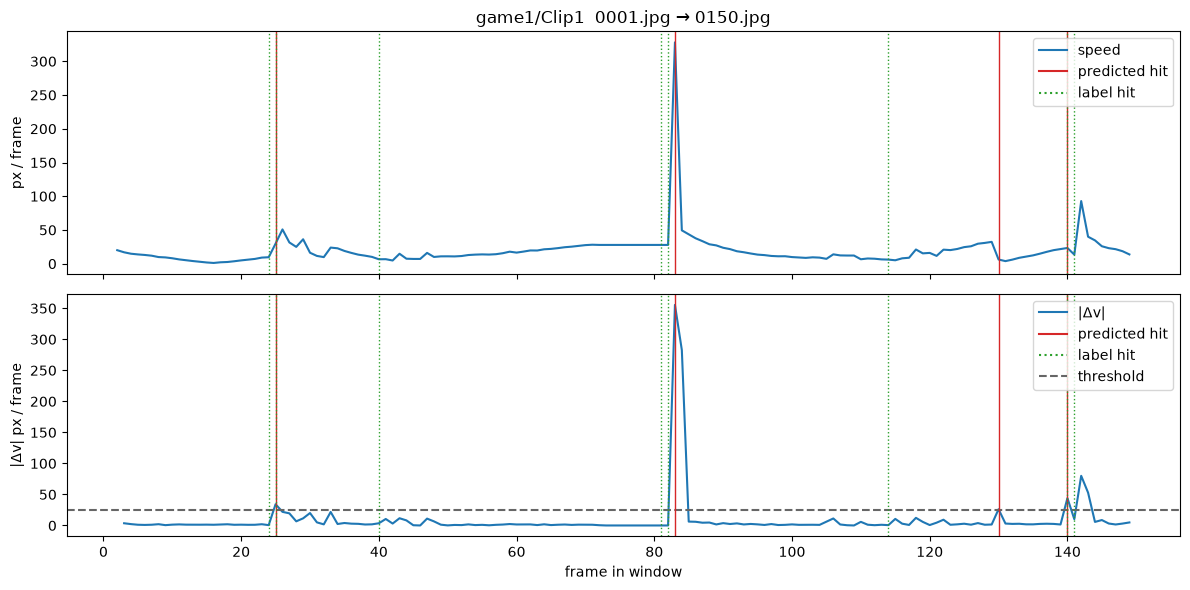

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ||Δvelocity|| in px/frame. Captures magnitude and direction changes.
VELOCITY_CHANGE_PX = 25.0
# Quiet level for rearm. Always >= 0 for ||Δv||, so keep this above 0.
REARM = 5.0
MIN_GAP = 5

n = len(steps)
# Frame-to-frame velocity from successive posteriors (px/frame).
velocity = np.full((n, 2), np.nan)
speed = np.full(n, np.nan)
velocity_change = np.full(n, np.nan)
for i in range(1, n):
    prev, step = steps[i - 1], steps[i]
    if prev is None or step is None:
        continue
    velocity[i] = step["post"] - prev["post"]
    speed[i] = float(np.linalg.norm(velocity[i]))
for i in range(1, n):
    if np.isfinite(velocity[i]).all() and np.isfinite(velocity[i - 1]).all():
        velocity_change[i] = float(np.linalg.norm(velocity[i] - velocity[i - 1]))

predicted = []
armed = True
last_hit = None
fell = False
for i in range(n):
    cur = velocity_change[i]
    if not np.isfinite(cur):
        continue
    # The drop below REARM is usually the next frame, still inside MIN_GAP.
    if last_hit is not None and fell and i - last_hit >= MIN_GAP:
        armed = True
    prev = velocity_change[i - 1] if i else np.nan
    gap_ok = last_hit is None or i - last_hit >= MIN_GAP
    crossed = (
        not np.isfinite(prev) or prev < VELOCITY_CHANGE_PX
    ) and cur >= VELOCITY_CHANGE_PX
    if armed and gap_ok and crossed:
        predicted.append(i)
        armed = False
        fell = False
        last_hit = i
    if cur < REARM:
        fell = True

label_hits = [i for i, frame in enumerate(frames) if frame["status"] == 1]

if predicted:
    for i in predicted:
        print(
            f"{frames[i]['file']}  speed={speed[i]:6.1f}  "
            f"|Δv|={velocity_change[i]:6.1f}"
        )
else:
    print("no predicted hits")

x = np.arange(n)
fig, (ax_speed, ax_change) = plt.subplots(2, 1, sharex=True, figsize=(12, 6))
ax_speed.plot(x, speed, color="C0")
ax_change.plot(x, velocity_change, color="C0")
ax_change.axhline(VELOCITY_CHANGE_PX, color="0.4", ls="--")
for i in predicted:
    ax_speed.axvline(i, color="C3", lw=1)
    ax_change.axvline(i, color="C3", lw=1)
for i in label_hits:
    ax_speed.axvline(i, color="C2", lw=1, ls=":")
    ax_change.axvline(i, color="C2", lw=1, ls=":")

ax_speed.set_ylabel("px / frame")
ax_change.set_ylabel("|Δv| px / frame")
ax_change.set_xlabel("frame in window")
ax_speed.set_title(f"{GAME}/{CLIP}  {frames[0]['file']} → {frames[-1]['file']}")
marks = [
    Line2D([0], [0], color="C0", label="speed"),
    Line2D([0], [0], color="C3", label="predicted hit"),
    Line2D([0], [0], color="C2", ls=":", label="label hit"),
]
ax_speed.legend(handles=marks, loc="upper right")
ax_change.legend(
    handles=[
        Line2D([0], [0], color="C0", label="|Δv|"),
        Line2D([0], [0], color="C3", label="predicted hit"),
        Line2D([0], [0], color="C2", ls=":", label="label hit"),
        Line2D([0], [0], color="0.4", ls="--", label="threshold"),
    ],
    loc="upper right",
)
fig.tight_layout()
plt.show()


In [3]:
FPS = 30.0
MAX_LAG = 8

actual = [i for i, frame in enumerate(frames) if frame["status"] == 1]
candidates = []
for a in actual:
    for p in predicted:
        lag = abs(p - a)
        if lag <= MAX_LAG:
            candidates.append((lag, a, p))
candidates.sort()

used_actual = set()
used_pred = set()
matches = []
for _lag, a, p in candidates:
    if a in used_actual or p in used_pred:
        continue
    used_actual.add(a)
    used_pred.add(p)
    matches.append((a, p))
matches.sort()

for a, p in matches:
    dt = p - a
    print(
        f"{frames[a]['file']} → {frames[p]['file']}  "
        f"{dt:+d} frames  {dt / FPS * 1000:+.0f} ms"
    )

missed = [frames[i]["file"] for i in actual if i not in used_actual]
extra = [frames[i]["file"] for i in predicted if i not in used_pred]
abs_err = [abs(p - a) for a, p in matches]
if abs_err:
    mean = float(np.mean(abs_err))
    median = float(np.median(abs_err))
    err_txt = (
        f"mean {mean:.1f} frames ({mean / FPS * 1000:.0f} ms)  "
        f"median {median:.1f} frames ({median / FPS * 1000:.0f} ms)"
    )
else:
    err_txt = "mean —  median —"
print(
    f"matched {len(matches)}/{len(actual)} labels, "
    f"{len(matches)}/{len(predicted)} predictions  {err_txt}"
)
print("unmatched labels: " + (" ".join(missed) if missed else "none"))
print("unmatched predictions: " + (" ".join(extra) if extra else "none"))


0083.jpg → 0084.jpg  +1 frames  +33 ms
0142.jpg → 0143.jpg  +1 frames  +33 ms
matched 2/8 labels, 2/2 predictions  mean 1.0 frames (33 ms)  median 1.0 frames (33 ms)
unmatched labels: 0025.jpg 0026.jpg 0041.jpg 0082.jpg 0115.jpg 0141.jpg
unmatched predictions: none


In [4]:
def _xy(xy) -> str:
    if xy is None:
        return "(     —,      —)"
    return f"({xy[0]:7.1f},{xy[1]:7.1f})"


def _num(value) -> str:
    if not np.isfinite(value):
        return "   —"
    return f"{value:6.1f}"


def shots_from(hits: list[int]) -> list[dict]:
    hits = sorted(set(hits))
    rows = []
    if not hits:
        return rows
    last = max((i for i, step in enumerate(steps) if step is not None), default=None)
    for k, start_i in enumerate(hits):
        open_shot = k == len(hits) - 1
        end_i = last if open_shot else hits[k + 1]
        if end_i is None or end_i < start_i:
            continue
        start_step = steps[start_i]
        end_step = steps[end_i]
        start_xy = None if start_step is None else start_step["post"]
        end_xy = None if end_step is None else end_step["post"]
        n_frames = end_i - start_i
        segment = speed[start_i + 1 : end_i + 1]
        finite = segment[np.isfinite(segment)]
        path = float(finite.mean()) if finite.size else float("nan")
        if start_xy is not None and end_xy is not None and n_frames > 0:
            line = float(np.linalg.norm(end_xy - start_xy) / n_frames)
        else:
            line = float("nan")
        rows.append(
            {
                "start": frames[start_i]["file"],
                "end": frames[end_i]["file"],
                "start_xy": start_xy,
                "end_xy": end_xy,
                "frames": n_frames,
                "path": path,
                "line": line,
                "open": open_shot,
            }
        )
    return rows


def print_shots(title: str, hits: list[int]) -> None:
    print(title)
    rows = shots_from(hits)
    if not rows:
        print("  none")
        return
    print(
        f"  {'start':<10}{'end':<10}{'start xy':>18}  {'end xy':>18}"
        f"  {'frames':>6}  {'path':>6}  {'line':>6}"
    )
    for row in rows:
        flag = "  open" if row["open"] else ""
        print(
            f"  {row['start']:<10}{row['end']:<10}{_xy(row['start_xy']):>18}"
            f"  {_xy(row['end_xy']):>18}  {row['frames']:6d}"
            f"  {_num(row['path'])}  {_num(row['line'])}{flag}"
        )


print("path = mean step speed, line = straight-line speed, both px/frame")
print_shots("label shots", [i for i, frame in enumerate(frames) if frame["status"] == 1])
print()
print_shots("detected shots", predicted)


path = mean step speed, line = straight-line speed, both px/frame
label shots
  start     end                 start xy              end xy  frames    path    line
  0025.jpg  0026.jpg   (  580.0,  294.8)   (  608.7,  286.7)       1    29.8    29.8
  0026.jpg  0041.jpg   (  608.7,  286.7)   (  821.7,  117.1)      15    20.3    18.2
  0041.jpg  0082.jpg   (  821.7,  117.1)   (  440.1,  431.9)      41    12.6    12.1
  0082.jpg  0083.jpg   (  440.1,  431.9)   (  440.1,  431.9)       1     0.0     0.0
  0083.jpg  0115.jpg   (  440.1,  431.9)   (  825.0,  114.7)      32    18.3    15.6
  0115.jpg  0141.jpg   (  825.0,  114.7)   (  789.5,  504.4)      26    16.8    15.1
  0141.jpg  0142.jpg   (  789.5,  504.4)   (  783.6,  492.3)       1    13.5    13.5
  0142.jpg  0150.jpg   (  783.6,  492.3)   (  715.8,  231.9)       8    33.8    33.6  open

detected shots
  start     end                 start xy              end xy  frames    path    line
  0084.jpg  0143.jpg   (  418.0,  362.0)   (  768.